# Lab 05 · Simple Linear Regression
**CS-3105 Machine Learning Lab** · Lab Instructor: Engr. Muhammad Awais

**CLO 7** (C-3 Apply, PLO 4 Investigation): *Apply machine learning algorithms and assess their performance using appropriate evaluation metrics.*

**Goal:** build a complete price predictor for one car on real data: prepare the data, split it, train a simple linear regression with the least squares method, test it on unseen ads, and use it.

**Data:** `pakistan_used_cars_clean.csv`, the cleaned OLX Pakistan used-car ads from Lab 03 (Open Data Pakistan, 2021). Use the copy given with this lab so everyone has the same file.

**Rules:** label every output, e.g. `print("T5a:", ...)` · use `random_state=42` for the split · written answers go in Markdown cells · Runtime → Restart and run all before you submit · push to `ML-Lab-<RollNo>/Lab05/Lab05.ipynb` by the deadline announced in class (11:59 PM PKT).

**Name: Jawahir Ali | Roll No: 2024-SE-34**

### Setup (run first, do not edit)
Put `pakistan_used_cars_clean.csv` next to this notebook (Colab: folder icon → Upload).

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
pd.set_option('display.width', 140)

## Task 1 · Load and explore the real data
- **(a)** Load `pakistan_used_cars_clean.csv` and print its shape.
- **(b)** Keep only **Corolla GLI**, **Cash** ads, `Year` 2005–2018 and `Price_lakh` between 5 and 40. Save it as `gli` and print the shape.
- **(c)** Summary statistics (`describe()`) of `Age` and `Price_lakh`.
- **(d)** The correlation between `Age` and `Price_lakh`.
- **(e)** A scatter plot of `Price_lakh` against `Age`, with a title and axis labels.

**Write (Markdown):** is a straight line a sensible model for this data? Use (d) and (e).

T1a: (20484, 11)
T1b: (796, 11)
T1c:
               Age  Price_lakh
count  796.000000  796.000000
mean     6.445980   16.586237
std      3.107847    3.984407
min      2.000000    6.543210
25%      4.000000   13.500000
50%      6.000000   16.500000
75%      9.000000   19.500000
max     15.000000   30.000000

T1d: -0.8956521001869919

T1e:


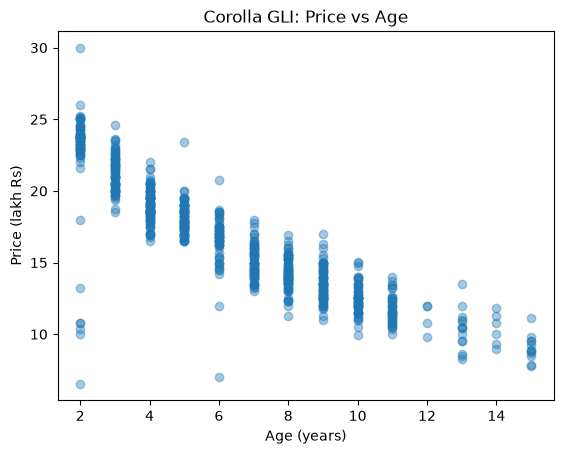

In [45]:
df=pd.read_csv("pakistan_used_cars_clean.csv")
print("T1a:",df.shape)

gli=df[(df["Model"]=="Corolla GLI") & (df["Transaction Type"]=="Cash")
    & df["Year"].between(2005,2018) & df["Price_lakh"].between(5,40)]
print("T1b:",gli.shape)

print("T1c:\n",gli[["Age","Price_lakh"]].describe())
print("\nT1d:",gli["Age"].corr(gli["Price_lakh"]))

print()
print("T1e:")
plt.scatter(gli["Age"],gli["Price_lakh"],alpha=0.4)
plt.title("Corolla GLI: Price vs Age")
plt.xlabel("Age (years)")
plt.ylabel("Price (lakh Rs)")
plt.show()            

    

*Yes, a line makes sense. The correlation is about `-0.89` . It's strong and negative (older means cheaper), and the scatter plot falls roughly along a line.*

## Task 2 · Features, target and the train/test split
- **(a)** `X` = the `Age` column as a **2-D** table, `y` = `Price_lakh`. Print both shapes.
- **(b)** Split 80 % train / 20 % test with `train_test_split(..., test_size=0.2, random_state=42)`. Print the four shapes.

In [46]:
X=gli[["Age"]]
y=gli["Price_lakh"]
print("T2a:",X.shape,y.shape)

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print("T2b:",X_train.shape,X_test.shape,y_train.shape,y_test.shape)


T2a: (796, 1) (796,)
T2b: (636, 1) (160, 1) (636,) (160,)


## Task 3 · Least squares with NumPy (training data only)
Use only `X_train` and `y_train`, and NumPy (no scikit-learn):
- **(a)** The means x̄ and ȳ.
- **(b)** The slope b₁ = Σ(x − x̄)(y − ȳ) / Σ(x − x̄)² and the intercept b₀ = ȳ − b₁x̄.
- **(c)** **Write (Markdown):** what b₁ and b₀ mean for a Corolla GLI, with units.

In [47]:
x=X_train["Age"].to_numpy()
yv=y_train.to_numpy()

x_bar,y_bar=x.mean(),yv.mean()
print("T3a:x_baris:",x_bar,"y_bar is:",y_bar)

b1=np.sum((x-x_bar)*(yv-y_bar))/np.sum((x-x_bar)**2)
b0=y_bar-b1*x_bar

print("T3b: b1=",b1,"b0=",b0)


T3a:x_baris: 6.382075471698113 y_bar is: 16.653325314465405
T3b: b1= -1.1459556866983842 b0= 23.96690099419613


*b₁ ≈ −1.15: each extra year of age lowers a Corolla GLI's price by about 1.15 lakh rupees (roughly Rs 115,000).   
b₀ ≈ 23.97: a brand-new (age 0) car is predicted at about 24 lakh rupees.*

## Task 4 · Train the model with scikit-learn
- **(a)** Create a `LinearRegression()` model, fit it on the **training** data and print the slope (`coef_`) and intercept (`intercept_`).
- **(b)** Show with `np.isclose` that they equal your Task 3 values.

In [48]:
model=LinearRegression()
model.fit(X_train,y_train)    # train on TRAINING data only
print("T4a slope:",model.coef_[0],"intercept:",model.intercept_)

print("T4b:",np.isclose(model.coef_[0],b1),np.isclose(model.intercept_,b0))


T4a slope: -1.1459556866983838 intercept: 23.966900994196127
T4b: True True


## Task 5 · Evaluate on the test set
- **(a)** Predict the test prices. Compute MAE, MSE, RMSE and R² **with the formulas** in NumPy.
- **(b)** Check MAE, MSE and R² with `sklearn.metrics`.
- **(c)** Train R² and test R². Is the model overfitting?
- **(d)** Baseline: predict the **training mean** for every test ad. Its MAE and R².

**Write (Markdown):** explain MAE and R² of your model in plain words, and how much better it is than the baseline.

In [49]:
y_pred=model.predict(X_test)
err=y_test-y_pred

mae=np.mean(np.abs(err))
mse=np.mean(err**2)
rmse=np.sqrt(mse)
sse=np.sum(err**2)
sst=np.sum((y_test-y_test.mean())**2)
r2=1-sse/sst

print("T5a:",mae,mse,rmse,r2)

print("T5b:",mean_absolute_error(y_test,y_pred),
      mean_squared_error(y_test,y_pred),
      r2_score(y_test,y_pred))
print("T5c train R2:",r2_score(y_train,model.predict(X_train)))
print("T5c test R2:",r2_score(y_test,y_pred))

base=np.full(len(y_test),y_train.mean())
print("T5d baseline MAE:",mean_absolute_error(y_test,base))

print("T5d baseline R2:",r2_score(y_test,base))



T5a: 1.1848658196422566 2.704315367423671 1.644480272737764 0.8451747677868002
T5b: 1.1848658196422566 2.704315367423671 0.8451747677868002
T5c train R2: 0.7896560758820064
T5c test R2: 0.8451747677868002
T5d baseline MAE: 3.5043950314465406
T5d baseline R2: -0.006377644420647366


*Reading the results:*

*(c) Not overfitting. Train R² (≈0.79) and test R² (≈0.85) are close. Overfitting would show a high train score and a much lower test score.
Write (MAE): predictions are off by about 1.2 lakh (Rs 118,000) on average.
Write (R²): age explains about 85% of the variation in price. Do not say "the model is 85% accurate", because the handout marks that as wrong.
Vs baseline: MAE drops from 3.50 to 1.18 lakh, about 3× smaller error. The baseline R² is roughly 0 by definition.*

## Task 6 · Visualise the line and the errors
- **(a)** One plot: training ads (grey), test ads, and the fitted line. Title, labels, legend.
- **(b)** A residual plot for the test set: residual (y − ŷ) against predicted price, with a line at 0.
- **(c)** The five test ads with the largest absolute error: `Year`, `KMs Driven`, `Registered City`, actual and predicted price.

**Write (Markdown):** does the residual plot show a curve or a funnel? Are the largest errors mistakes of the model or of the data?

T6a:


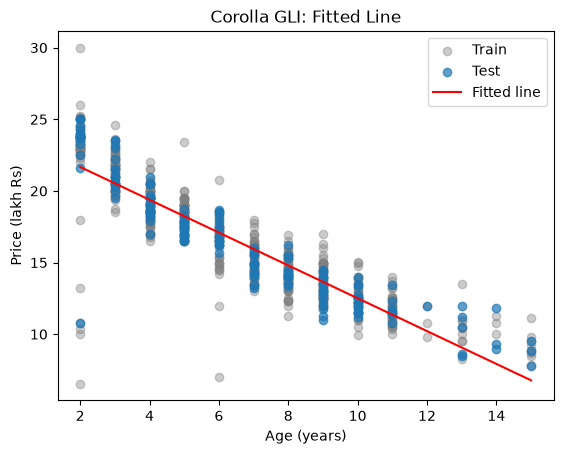

T6b:


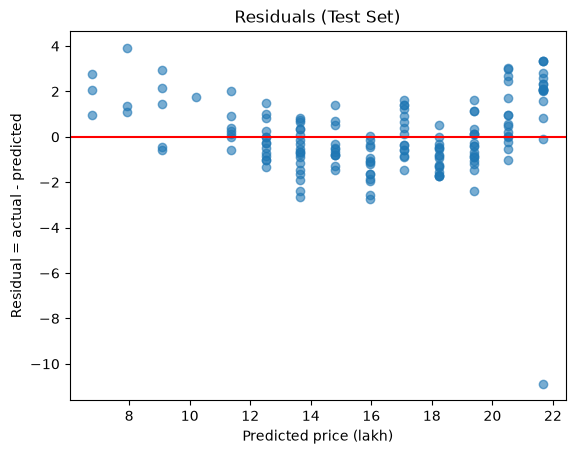

T6c:
        Year  KMs Driven Registered City  Price_lakh  Predicted
18857  2018         NaN         Unknown       10.80  21.674990
20280  2006    220000.0       Islamabad       11.85   7.923521
17363  2018         NaN         Unknown       25.00  21.674990
18980  2018         NaN         Unknown       25.00  21.674990
16557  2018       300.0         Unknown       25.00  21.674990


In [50]:
# (a) data + fitted line
print("T6a:")
plt.scatter(X_train,y_train,color="grey",alpha=0.4,label="Train")
plt.scatter(X_test,y_test,color="tab:blue",alpha=0.7,label="Test")
line_x= pd.DataFrame({"Age": np.arange(X["Age"].min(), X["Age"].max() + 1)})
plt.plot(line_x, model.predict(line_x), color="red", label="Fitted line")
plt.title("Corolla GLI: Fitted Line")
plt.xlabel("Age (years)")
plt.ylabel("Price (lakh Rs)")
plt.legend()
plt.show()


# (b) residual plot
print("T6b:")
plt.scatter(y_pred, err, alpha=0.6)
plt.axhline(0, color="red")
plt.title("Residuals (Test Set)")
plt.xlabel("Predicted price (lakh)")
plt.ylabel("Residual = actual - predicted")
plt.show()


# (c) five biggest errors
worst = err.abs().sort_values(ascending=False).head(5).index
out = gli.loc[worst, ["Year", "KMs Driven", "Registered City", "Price_lakh"]].copy()
out["Predicted"] = pd.Series(y_pred, index=y_test.index).loc[worst]
print("T6c:\n", out)


<b>Residual plot:</b> *compare it with the two shapes. A curve means a line is the wrong shape. A funnel means errors grow with price. Describe what you actually see in your plot.*  

<b>Largest errors:</b> *in my run they are mostly 2018 ads with missing KMs and "Unknown" city, priced at 25 or 10.8 lakh. These look like data problems (odd or unreliable ads), not model mistakes, because age alone can't explain them.*

## Task 7 · Use the model
- **(a)** Predict the price of a 2018, a 2015 and a 2010 Corolla GLI (age = 2020 − year), using a DataFrame with an `Age` column.
- **(b)** Predict the price of a 1995 Corolla GLI (age 25).

**Write (Markdown):** is the answer in (b) believable? Why not?

In [51]:
new = pd.DataFrame({"Age": [2, 5, 10]})           # 2018, 2015, 2010
print("T7a:", model.predict(new))                 # ≈ [21.67, 18.24, 12.51]

print("T7b:", model.predict(pd.DataFrame({"Age": [25]})))   # ≈ [-4.68]


T7a: [21.67498962 18.23712256 12.50734413]
T7b: [-4.68199117]


*No, it isn't believable. A negative price is impossible. The model was trained on ages 2 to 15, so age 25 is extrapolation far outside the data. The line keeps falling forever, but real prices level off for old cars. The handout's table makes the same point. In the PDF the minus sign is missing, so it says 4.7 lakh, but the real output is −4.7.*

## Task 8 · Reflection (Markdown cell)
Write 3–5 sentences: the steps you followed to build the model, why the model is judged on the test set and not the training set, which number you would tell a car buyer and why, and one limitation of using age alone.

### 1. Steps   
1. Load(Previous lab (Lab03) cleaned data/csv file ).
2. Choose X and y
3. Split
4. Fit
5. Evaluate
6. Use

### 2. Why Test, not Train
The Training score only shows how well the model memorised the known data. The test set/data shows how it performs on new data.

### 3. Which number to tell a car buyer:
MAE(about Rs 118,000 off on average). It is in rupees and easy to understand, while R² is a pure ratio.

### 4. Limitation: 
Age alone ignores mileage, condition, city, and seller, and it extrapolates badly for very old cars.

 